# Лабораторная работа №5. Квантовые сумматоры. Алгоритм Гровера
**Студент:** Вабищевич Илья (группа ИИ-28)  
**Вариант:** 3  

**Цель работы:** ознакомление с выполнением простого сложения с помощью квантовых схем, построением обратимых булевых схем с очисткой вспомогательных кубитов (uncomputation), моделированием деполяризующего шума, а также реализацией и исследованием алгоритма Гровера в квантовых системах (Qiskit).

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.quantum_info import Statevector, Operator

sim = AerSimulator()
print("Симулятор AerSimulator успешно инициализирован.")

Симулятор AerSimulator успешно инициализирован.


---
## Задание 1. Полный сумматор и многоразрядный квантовый сумматор

Полный сумматор принимает два входных бита $A$, $B$ и входной бит переноса $X$ (`carry in`), вычисляя бит суммы $S$ и выходной бит переноса $C$ (`carry out`):
$$S = A \oplus B \oplus X, \qquad C = (A \wedge B) \vee (A \wedge X) \vee (B \wedge X) = (A \wedge B) \oplus (X \wedge (A \oplus B)).$$

### 1.1 Полный сумматор для входов $A=1, B=0, X=1$

In [2]:
def build_full_adder_5q(a_val: int = 0, b_val: int = 0, x_val: int = 0, measure: bool = True) -> QuantumCircuit:
    """
    Полный сумматор на 5 кубитах (q[0]=A, q[1]=B, q[2]=X, q[3]=S, q[4]=C)
    только из вентилей X, CX и CCX без промежуточных измерений и без ancilla.
    """
    qc = QuantumCircuit(5, 2) if measure else QuantumCircuit(5)
    if a_val:
        qc.x(0)
    if b_val:
        qc.x(1)
    if x_val:
        qc.x(2)

    # 1. C ^= (A & B)
    qc.ccx(0, 1, 4)
    # 2. S ^= A ^ B
    qc.cx(0, 3)
    qc.cx(1, 3)
    # 3. C ^= X & (A ^ B)
    qc.ccx(2, 3, 4)
    # 4. S ^= X -> итого S = A ^ B ^ X
    qc.cx(2, 3)

    if measure:
        qc.measure(3, 0)  # c[0] = S
        qc.measure(4, 1)  # c[1] = C
    return qc

# 1) Вектор состояния без измерений для A=1, B=0, X=1
qc_101_sv = build_full_adder_5q(1, 0, 1, measure=False)
sv_101 = Statevector.from_instruction(qc_101_sv)
probs_101 = sv_101.probabilities_dict()
print("Ненулевые компоненты вектора состояния |q4 q3 q2 q1 q0> = |C S X B A>:")
for state_str, prob in probs_101.items():
    print(f"  |{state_str}> : амплитуда = {sv_101[int(state_str, 2)]:.4f}, вероятность = {prob:.4f}")

# 2) Распределение результатов с измерениями (shots=1024)
qc_101_meas = build_full_adder_5q(1, 0, 1, measure=True)
counts_101 = sim.run(qc_101_meas, shots=1024, seed_simulator=42).result().get_counts()
print("\nРаспределение результатов измерения (формат 'c[1]c[0]' = 'C S', shots=1024):", counts_101)
print(qc_101_meas.draw(output="text"))

Ненулевые компоненты вектора состояния |q4 q3 q2 q1 q0> = |C S X B A>:
  |10101> : амплитуда = 1.0000+0.0000j, вероятность = 1.0000

Распределение результатов измерения (формат 'c[1]c[0]' = 'C S', shots=1024): {'10': 1024}
     ┌───┐                            
q_0: ┤ X ├──■────■────────────────────
     └───┘  │    │                    
q_1: ───────■────┼────■───────────────
     ┌───┐  │    │    │               
q_2: ┤ X ├──┼────┼────┼────■────■─────
     └───┘  │  ┌─┴─┐┌─┴─┐  │  ┌─┴─┐┌─┐
q_3: ───────┼──┤ X ├┤ X ├──■──┤ X ├┤M├
          ┌─┴─┐└───┘└───┘┌─┴─┐└┬─┬┘└╥┘
q_4: ─────┤ X ├──────────┤ X ├─┤M├──╫─
          └───┘          └───┘ └╥┘  ║ 
c: 2/═══════════════════════════╩═══╩═
                                1   0 


**Объяснение для $A=1, B=0, X=1$:**
В Qiskit биты нумеруются справа налево ($|q_4 q_3 q_2 q_1 q_0\rangle = |C\, S\, X\, B\, A\rangle$).
Для входа $A=1, B=0, X=1$ арифметическая сумма равна $1 + 0 + 1 = 2 = 10_2$, поэтому младший разряд суммы $S = 0$, а перенос в старший разряд $C = 1$. Вектор состояния равен $|10101\rangle$ ($q_0=A=1, q_1=B=0, q_2=X=1, q_3=S=0, q_4=C=1$), а все 1024 измерения дают строку `'10'` ($C=1, S=0$), что в точности соответствует строке таблицы истинности `1 | 0 | 1 -> S=0, C=1`.

---
### 1.2 Проверка 5-кубитного полного сумматора на всех 8 наборах входов

In [3]:
rows_fa5 = []
for a in (0, 1):
    for b in (0, 1):
        for x in (0, 1):
            exp_s = a ^ b ^ x
            exp_c = (a & b) | (a & x) | (b & x)
            qc = build_full_adder_5q(a, b, x, measure=True)
            cnt = sim.run(qc, shots=256, seed_simulator=42).result().get_counts()
            assert len(cnt) == 1, f"Ожидался детерминированный исход, получено {cnt}"
            bitstr = next(iter(cnt.keys()))  # 'C S'
            got_c, got_s = int(bitstr[0]), int(bitstr[1])
            assert got_s == exp_s and got_c == exp_c, f"Несовпадение при A={a}, B={b}, X={x}"
            rows_fa5.append({
                "A": a, "B": b, "X": x,
                "S (ожид.)": exp_s, "C (ожид.)": exp_c,
                "S (получ.)": got_s, "C (получ.)": got_c,
                "Проверка (assert)": "OK"
            })

df_fa5 = pd.DataFrame(rows_fa5)
print("Сводная таблица проверки 5-кубитного полного сумматора:")
print(df_fa5.to_string(index=False))

Сводная таблица проверки 5-кубитного полного сумматора:
 A  B  X  S (ожид.)  C (ожид.)  S (получ.)  C (получ.) Проверка (assert)
 0  0  0          0          0           0           0                OK
 0  0  1          1          0           1           0                OK
 0  1  0          1          0           1           0                OK
 0  1  1          0          1           0           1                OK
 1  0  0          1          0           1           0                OK
 1  0  1          0          1           0           1                OK
 1  1  0          0          1           0           1                OK
 1  1  1          1          1           1           1                OK


---
### 1.3 Полный сумматор из двух полусумматоров и вентиля ИЛИ и сравнение реализаций

In [4]:
def build_full_adder_2ha_or(a_val: int = 0, b_val: int = 0, x_val: int = 0, measure: bool = True) -> QuantumCircuit:
    """
    Полный сумматор из двух полусумматоров и вентиля ИЛИ:
      q[0]=A, q[1]=B, q[2]=X
      q[3]=S1 (сумма ПС1 = A ^ B), q[4]=C1 (перенос ПС1 = A & B)
      q[5]=S  (сумма ПС2 = S1 ^ X), q[6]=C2 (перенос ПС2 = S1 & X)
      q[7]=C  (выход ИЛИ = C1 | C2)
    """
    qc = QuantumCircuit(8, 2) if measure else QuantumCircuit(8)
    if a_val:
        qc.x(0)
    if b_val:
        qc.x(1)
    if x_val:
        qc.x(2)

    # Полусумматор 1 (A, B -> S1=q[3], C1=q[4])
    qc.cx(0, 3)
    qc.cx(1, 3)
    qc.ccx(0, 1, 4)

    # Полусумматор 2 (S1=q[3], X=q[2] -> S=q[5], C2=q[6])
    qc.cx(3, 5)
    qc.cx(2, 5)
    qc.ccx(3, 2, 6)

    # Вентиль ИЛИ (C1=q[4], C2=q[6] -> C=q[7])
    qc.cx(4, 7)
    qc.cx(6, 7)
    qc.ccx(4, 6, 7)

    if measure:
        qc.measure(5, 0)  # S
        qc.measure(7, 1)  # C
    return qc

rows_fa8 = []
for a in (0, 1):
    for b in (0, 1):
        for x in (0, 1):
            exp_s = a ^ b ^ x
            exp_c = (a & b) | (a & x) | (b & x)
            qc = build_full_adder_2ha_or(a, b, x, measure=True)
            cnt = sim.run(qc, shots=256, seed_simulator=42).result().get_counts()
            assert len(cnt) == 1
            bitstr = next(iter(cnt.keys()))
            got_c, got_s = int(bitstr[0]), int(bitstr[1])
            assert got_s == exp_s and got_c == exp_c
            rows_fa8.append({
                "A": a, "B": b, "X": x,
                "S (ожид.)": exp_s, "C (ожид.)": exp_c,
                "S (получ.)": got_s, "C (получ.)": got_c,
                "Проверка (assert)": "OK"
            })

print("Проверка схемы из 2 полусумматоров и вентиля ИЛИ на всех 8 наборах: все assert пройдены!")

qc5_bare = build_full_adder_5q(0, 0, 0, measure=False)
qc8_bare = build_full_adder_2ha_or(0, 0, 0, measure=False)

comp_df = pd.DataFrame([
    {
        "Реализация": "5-кубитная (прямая)",
        "Число кубитов": qc5_bare.num_qubits,
        "Число CX": qc5_bare.count_ops().get("cx", 0),
        "Число CCX": qc5_bare.count_ops().get("ccx", 0),
        "Глубина qc.depth()": qc5_bare.depth()
    },
    {
        "Реализация": "8-кубитная (2 ПС + ИЛИ)",
        "Число кубитов": qc8_bare.num_qubits,
        "Число CX": qc8_bare.count_ops().get("cx", 0),
        "Число CCX": qc8_bare.count_ops().get("ccx", 0),
        "Глубина qc.depth()": qc8_bare.depth()
    }
])
print("\nСравнение двух реализаций полного сумматора:")
print(comp_df.to_string(index=False))

Проверка схемы из 2 полусумматоров и вентиля ИЛИ на всех 8 наборах: все assert пройдены!

Сравнение двух реализаций полного сумматора:
             Реализация  Число кубитов  Число CX  Число CCX  Глубина qc.depth()
    5-кубитная (прямая)              5         3          2                   5
8-кубитная (2 ПС + ИЛИ)              8         6          3                   7


**Вывод по сравнению реализаций полного сумматора:**
5-кубитная реализация значительно экономичнее по всем метрикам: она использует **5 кубитов вместо 8**, **3 вентиля CX вместо 6**, **2 вентиля CCX вместо 3** и имеет **глубину 5 вместо 7**. Причина заключается в том, что промежуточная сумма $A \oplus B$ формируется непосредственно на выходном кубите $S$ до прибавления $X$, а поскольку переносы $C_1 = A \wedge B$ и $C_2 = X \wedge (A \oplus B)$ не могут быть равны 1 одновременно ($C_1 \wedge C_2 = 0$), операция $C_1 \vee C_2$ заменяется на прямое сложение по модулю 2 ($C_1 \oplus C_2$) в один и тот же целевой кубит $C$ без отдельного вентиля ИЛИ и без дополнительных кубитов.

---
### 1.4 Многоразрядный сумматор (2, 3 и 4 бита) и проверка всех 256 пар $(a, b)$

In [5]:
def build_nbit_adder(n_bits: int, a_int: int = 0, b_int: int = 0, measure: bool = True) -> QuantumCircuit:
    """
    Строит n-разрядный сумматор с последовательным переносом (ripple-carry).
    Входы: n-битные числа a и b. Выход: (n+1)-битная сумма s = a + b.
    """
    reg_a = QuantumRegister(n_bits, "a")
    reg_b = QuantumRegister(n_bits, "b")
    reg_c = QuantumRegister(n_bits + 1, "c")
    reg_s = QuantumRegister(n_bits, "s")

    if measure:
        creg = ClassicalRegister(n_bits + 1, "sum")
        qc = QuantumCircuit(reg_a, reg_b, reg_c, reg_s, creg)
    else:
        qc = QuantumCircuit(reg_a, reg_b, reg_c, reg_s)

    for i in range(n_bits):
        if (a_int >> i) & 1:
            qc.x(reg_a[i])
        if (b_int >> i) & 1:
            qc.x(reg_b[i])

    for i in range(n_bits):
        qc.ccx(reg_a[i], reg_b[i], reg_c[i + 1])
        qc.cx(reg_a[i], reg_s[i])
        qc.cx(reg_b[i], reg_s[i])
        qc.ccx(reg_c[i], reg_s[i], reg_c[i + 1])
        qc.cx(reg_c[i], reg_s[i])

    if measure:
        for i in range(n_bits):
            qc.measure(reg_s[i], creg[i])
        qc.measure(reg_c[n_bits], creg[n_bits])
    return qc

# Программная проверка всех 16 * 16 = 256 пар (a, b) для 4-битного сумматора
for a_val in range(16):
    for b_val in range(16):
        qc4 = build_nbit_adder(4, a_val, b_val, measure=True)
        cnt = sim.run(qc4, shots=16, seed_simulator=42).result().get_counts()
        assert len(cnt) == 1
        got_sum = int(next(iter(cnt.keys())), 2)
        assert got_sum == a_val + b_val, f"Ошибка для ({a_val}, {b_val}): получено {got_sum}"

print("Все 16 * 16 = 256 пар (a, b) для 4-битного сумматора успешно проверены программно (assert OK)!")

adder_stats = []
for nb in (2, 3, 4):
    qc_nb = build_nbit_adder(nb, 0, 0, measure=False)
    ops = qc_nb.count_ops()
    adder_stats.append({
        "Разрядность n": nb,
        "Число кубитов (4n+1)": qc_nb.num_qubits,
        "Число CX (3n)": ops.get("cx", 0),
        "Число CCX (2n)": ops.get("ccx", 0),
        "Глубина схемы": qc_nb.depth()
    })

df_adders = pd.DataFrame(adder_stats)
print("\nХарактеристики сумматоров для 2, 3 и 4 разрядов:")
print(df_adders.to_string(index=False))

Все 16 * 16 = 256 пар (a, b) для 4-битного сумматора успешно проверены программно (assert OK)!

Характеристики сумматоров для 2, 3 и 4 разрядов:
 Разрядность n  Число кубитов (4n+1)  Число CX (3n)  Число CCX (2n)  Глубина схемы
             2                     9              6               4              6
             3                    13              9               6              7
             4                    17             12               8              8


### Ответы на вопросы к Заданию 1

1. **Почему перенос $C$ полного сумматора нельзя вычислить одним вентилем CCX? Какие слагаемые для него нужны?**  
   Один вентиль Тоффоли (`CCX`) вычисляет конъюнкцию только двух входов ($A \wedge B$), что соответствует полусумматору. В полном сумматоре перенос возникает, когда **любые два** из трёх входов ($A, B, X$) равны 1:
   $$C = (A \wedge B) \vee (A \wedge X) \vee (B \wedge X) = (A \wedge B) \oplus (X \wedge (A \oplus B)).$$
   Таким образом, нужны два произведения (конъюнкции): $A \wedge B$ и $X \wedge (A \oplus B)$, для каждого из которых требуется свой вентиль `CCX`.

2. **Вентиль CX копирует классический бит, но не может скопировать произвольную суперпозицию. Как это связано с теоремой о запрете клонирования?**  
   Для произвольного состояния $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ применение `CX` к $|\psi\rangle|0\rangle$ даёт запутанное состояние $\alpha|00\rangle + \beta|11\rangle$, тогда как клонирование должно давать сепарабельное состояние $|\psi\rangle|\psi\rangle = \alpha^2|00\rangle + \alpha\beta|01\rangle + \alpha\beta|10\rangle + \beta^2|11\rangle$. Равенство выполняется только при $\alpha\beta = 0$, то есть для базисных состояний $|0\rangle$ и $|1\rangle$. Согласно теореме о запрете клонирования (no-cloning theorem), не существует линейного унитарного оператора, копирующего произвольное неизвестное квантовое состояние.

3. **Как можно уменьшить глубину 4-разрядного сумматора и какой ценой (дополнительные кубиты, вентили)?**  
   В последовательном сумматоре (ripple-carry) глубина растёт линейно $O(n)$, так как каждый разряд ждёт перенос из предыдущего. Глубину можно снизить до логарифмической $O(\log n)$ с помощью **сумматора с ускоренным переносом (carry-lookahead adder, например схема Драпера–Куткаро–Монро–Свора)**, где сигналы генерации $g_i = a_i \wedge b_i$ и распространения $p_i = a_i \oplus b_i$ объединяются бинарным деревом. Цена такого ускорения — дополнительные вспомогательные (`ancilla`) кубиты для хранения промежуточных переносов и увеличение общего числа вентилей `CCX` (включая вентили для обратного очищения `uncomputation`).

---
## Задание 2. Квантовая схема булевой функции по варианту (Вариант 3)

**Вариант 3:**
$$F(A, B, C, D) = (A \wedge \neg B) \vee (\neg C \wedge D).$$

1. Реализуем базовые логические подсхемы (`NOT`, `AND`, `OR`, `XOR`, `NAND`, `NOR`, `MAJ`), добавляющие вентили в переданную схему.
2. Построим две версии схемы:
   - **Базовая**: каждый промежуточный результат ($
eg B$, $
eg C$, $A \wedge 
eg B$, $
eg C \wedge D$, итоговое $ee$) вычисляется в отдельный `ancilla`-кубит (5 вспомогательных кубитов, всего 10 кубитов), результат копируется в выходной кубит `out`, после чего применяется `.inverse()` для возврата всех `ancilla` в $|0\rangle$.
   - **Оптимизированная**: использует всего 2 вспомогательных кубита для конъюнкций $A \wedge \neg B$ и $\neg C \wedge D$ (инверсия входных кубитов $B$ и $C$ выполняется на месте парой вентилей `X` вокруг `CCX`), а дизъюнкция `gate_or` вычисляется напрямую в выходной кубит `out`, после чего 2 `ancilla`-кубита очищаются через `.inverse()`.

In [6]:
# 2.1 Базовые логические элементы как модульные функции
def gate_not(qc: QuantumCircuit, a, out):
    """Записывает ¬a в кубит out (при начальном out=|0>)."""
    qc.cx(a, out)
    qc.x(out)

def gate_and(qc: QuantumCircuit, a, b, out):
    """out ^= (a ∧ b)"""
    qc.ccx(a, b, out)

def gate_or(qc: QuantumCircuit, a, b, out):
    """out ^= (a ∨ b) = a ⊕ b ⊕ (a ∧ b)"""
    qc.cx(a, out)
    qc.cx(b, out)
    qc.ccx(a, b, out)

def gate_xor(qc: QuantumCircuit, a, b, out):
    """out ^= (a ⊕ b)"""
    qc.cx(a, out)
    qc.cx(b, out)

def gate_nand(qc: QuantumCircuit, a, b, out):
    """Записывает ¬(a ∧ b) в кубит out (при out=|0>)."""
    qc.ccx(a, b, out)
    qc.x(out)

def gate_nor(qc: QuantumCircuit, a, b, out):
    """Записывает ¬(a ∨ b) в кубит out (при out=|0>)."""
    qc.cx(a, out)
    qc.cx(b, out)
    qc.ccx(a, b, out)
    qc.x(out)

def gate_maj(qc: QuantumCircuit, a, b, c, out):
    """out ^= MAJ(a, b, c) = (a∧b) ⊕ (a∧c) ⊕ (b∧c)"""
    qc.ccx(a, b, out)
    qc.ccx(a, c, out)
    qc.ccx(b, c, out)

def gate_and_not(qc: QuantumCircuit, a, b_neg, out):
    """Вычисляет out ^= (a ∧ ¬b_neg) без дополнительного ancilla-кубита для ¬b_neg."""
    qc.x(b_neg)
    gate_and(qc, a, b_neg, out)
    qc.x(b_neg)

# Классическая реализация F(A, B, C, D) = (A ∧ ¬B) ∨ (¬C ∧ D)
def classical_F_var3(A: int, B: int, C: int, D: int) -> int:
    return int((bool(A) and (not bool(B))) or ((not bool(C)) and bool(D)))

# Базовая квантовая схема (5 ancilla-кубитов)
def build_F_var3_basic(inputs=None, measure: bool = True) -> QuantumCircuit:
    qr_in = QuantumRegister(4, "in")
    qr_anc = QuantumRegister(5, "anc")
    qr_out = QuantumRegister(1, "out")
    if measure:
        cr_out = ClassicalRegister(1, "f")
        cr_anc = ClassicalRegister(5, "canc")
        qc = QuantumCircuit(qr_in, qr_anc, qr_out, cr_out, cr_anc)
    else:
        qc = QuantumCircuit(qr_in, qr_anc, qr_out)

    if inputs is not None:
        for i, bit in enumerate(inputs):
            if bit:
                qc.x(qr_in[i])

    comp = QuantumCircuit(qr_in, qr_anc, qr_out)
    gate_not(comp, qr_in[1], qr_anc[0])               # anc[0] = ¬B
    gate_not(comp, qr_in[2], qr_anc[1])               # anc[1] = ¬C
    gate_and(comp, qr_in[0], qr_anc[0], qr_anc[2])    # anc[2] = A ∧ ¬B
    gate_and(comp, qr_anc[1], qr_in[3], qr_anc[3])    # anc[3] = ¬C ∧ D
    gate_or(comp, qr_anc[2], qr_anc[3], qr_anc[4])    # anc[4] = (A ∧ ¬B) ∨ (¬C ∧ D)

    qc.compose(comp, inplace=True)
    qc.cx(qr_anc[4], qr_out[0])                       # Копирование на выходной кубит
    qc.compose(comp.inverse(), inplace=True)          # Очистка (uncomputation) всех ancilla

    if measure:
        qc.measure(qr_out[0], cr_out[0])
        qc.measure(qr_anc, cr_anc)
    return qc

# Оптимизированная квантовая схема (2 ancilla-кубита)
def build_F_var3_optimized(inputs=None, measure: bool = True) -> QuantumCircuit:
    qr_in = QuantumRegister(4, "in")
    qr_anc = QuantumRegister(2, "anc")
    qr_out = QuantumRegister(1, "out")
    if measure:
        cr_out = ClassicalRegister(1, "f")
        cr_anc = ClassicalRegister(2, "canc")
        qc = QuantumCircuit(qr_in, qr_anc, qr_out, cr_out, cr_anc)
    else:
        qc = QuantumCircuit(qr_in, qr_anc, qr_out)

    if inputs is not None:
        for i, bit in enumerate(inputs):
            if bit:
                qc.x(qr_in[i])

    comp = QuantumCircuit(qr_in, qr_anc, qr_out)
    gate_and_not(comp, qr_in[0], qr_in[1], qr_anc[0])  # anc[0] = A ∧ ¬B
    gate_and_not(comp, qr_in[3], qr_in[2], qr_anc[1])  # anc[1] = D ∧ ¬C

    qc.compose(comp, inplace=True)
    gate_or(qc, qr_anc[0], qr_anc[1], qr_out[0])       # out = anc[0] ∨ anc[1]
    qc.compose(comp.inverse(), inplace=True)           # Очистка anc[0..1] -> |00>

    if measure:
        qc.measure(qr_out[0], cr_out[0])
        qc.measure(qr_anc, cr_anc)
    return qc

print("Базовая схема F(A,B,C,D):")
print(build_F_var3_basic(measure=False).draw(output="text"))
print("\nОптимизированная схема F(A,B,C,D):")
print(build_F_var3_optimized(measure=False).draw(output="text"))

Базовая схема F(A,B,C,D):
                                                                             »
 in_0: ─────────────────■─────────────────────────────────────────────────■──»
                        │                                                 │  »
 in_1: ──■──────────────┼─────────────────────────────────────────────────┼──»
         │              │                                                 │  »
 in_2: ──┼────■─────────┼─────────────────────────────────────────────────┼──»
         │    │         │                                                 │  »
 in_3: ──┼────┼─────────┼────■───────────────────────────────────────■────┼──»
       ┌─┴─┐  │  ┌───┐  │    │                                       │    │  »
anc_0: ┤ X ├──┼──┤ X ├──■────┼───────────────────────────────────────┼────■──»
       └───┘┌─┴─┐├───┤  │    │                                       │    │  »
anc_1: ─────┤ X ├┤ X ├──┼────■───────────────────────────────────────■────┼──»
            └───┘└───┘┌─┴─

In [7]:
# 2.3 Проверка обеих схем на всех 2^4 = 16 входах (shots=256 >= 100)
rows_f3 = []
shots_test = 256

for idx in range(16):
    A, B, C, D = (idx >> 3) & 1, (idx >> 2) & 1, (idx >> 1) & 1, idx & 1
    f_cls = classical_F_var3(A, B, C, D)

    # Базовая схема
    qc_b = build_F_var3_basic((A, B, C, D), measure=True)
    cnt_b = sim.run(qc_b, shots=shots_test, seed_simulator=42 + idx).result().get_counts()
    assert len(cnt_b) == 1
    anc_b, f_b = next(iter(cnt_b.keys())).split(" ")
    assert anc_b == "00000", f"Базовая схема: ancilla не вернулись в |0>: {anc_b}"
    assert int(f_b) == f_cls

    # Оптимизированная схема
    qc_o = build_F_var3_optimized((A, B, C, D), measure=True)
    cnt_o = sim.run(qc_o, shots=shots_test, seed_simulator=142 + idx).result().get_counts()
    assert len(cnt_o) == 1
    anc_o, f_o = next(iter(cnt_o.keys())).split(" ")
    assert anc_o == "00", f"Оптимизированная схема: ancilla не вернулись в |0>: {anc_o}"
    assert int(f_o) == f_cls

    rows_f3.append({
        "A": A, "B": B, "C": C, "D": D,
        "F (классич.)": f_cls,
        "F (квант. баз.)": int(f_b),
        "Ancilla (баз.)": f"|{anc_b}>",
        "F (квант. опт.)": int(f_o),
        "Ancilla (опт.)": f"|{anc_o}>",
        "Статус": "OK (100%)"
    })

df_f3 = pd.DataFrame(rows_f3)
print("Таблица верификации F(A, B, C, D) = (A ∧ ¬B) ∨ (¬C ∧ D) на всех 16 входах:")
print(df_f3.to_string(index=False))

# 2.4 Сравнение характеристик базовой и оптимизированной схем
qc_b_bare = build_F_var3_basic(measure=False)
qc_o_bare = build_F_var3_optimized(measure=False)

df_comp_f3 = pd.DataFrame([
    {
        "Версия схемы": "Базовая (5 ancilla)",
        "Кубитов всего": qc_b_bare.num_qubits,
        "Вспом. кубитов": 5,
        "Вентилей CX": qc_b_bare.count_ops().get("cx", 0),
        "Вентилей CCX": qc_b_bare.count_ops().get("ccx", 0),
        "Вентилей X": qc_b_bare.count_ops().get("x", 0),
        "Глубина qc.depth()": qc_b_bare.depth()
    },
    {
        "Версия схемы": "Оптимизированная (2 ancilla)",
        "Кубитов всего": qc_o_bare.num_qubits,
        "Вспом. кубитов": 2,
        "Вентилей CX": qc_o_bare.count_ops().get("cx", 0),
        "Вентилей CCX": qc_o_bare.count_ops().get("ccx", 0),
        "Вентилей X": qc_o_bare.count_ops().get("x", 0),
        "Глубина qc.depth()": qc_o_bare.depth()
    }
])
print("\nСравнение базовой и оптимизированной схем:")
print(df_comp_f3.to_string(index=False))

Таблица верификации F(A, B, C, D) = (A ∧ ¬B) ∨ (¬C ∧ D) на всех 16 входах:
 A  B  C  D  F (классич.)  F (квант. баз.) Ancilla (баз.)  F (квант. опт.) Ancilla (опт.)    Статус
 0  0  0  0             0                0        |00000>                0           |00> OK (100%)
 0  0  0  1             1                1        |00000>                1           |00> OK (100%)
 0  0  1  0             0                0        |00000>                0           |00> OK (100%)
 0  0  1  1             0                0        |00000>                0           |00> OK (100%)
 0  1  0  0             0                0        |00000>                0           |00> OK (100%)
 0  1  0  1             1                1        |00000>                1           |00> OK (100%)
 0  1  1  0             0                0        |00000>                0           |00> OK (100%)
 0  1  1  1             0                0        |00000>                0           |00> OK (100%)
 1  0  0  0             1

**Объяснение (почему минимум по числу кубитов и минимум по глубине могут не совпадать):**
В нашем случае оптимизированная схема улучшила сразу и число кубитов (7 вместо 10), и глубину (7 вместо 13), так как два терма $(A \wedge \neg B)$ и $(\neg C \wedge D)$ зависят от непересекающихся пар входов и вычисляются полностью параллельно. Однако в общем случае уменьшение числа вспомогательных кубитов требует повторного использования одних и тех же `ancilla`-кубитов (последовательного вычисления и немедленной очистки промежуточных результатов), что превращает параллельные ветви схемы в последовательные и **увеличивает глубину**. Напротив, выделение дополнительных `ancilla`-кубитов позволяет распараллелить независимые подвыражения и уменьшить глубину ценой роста ширины схемы.

---
## Задание 3. Моделирование работы схемы с деполяризующим шумом

<>:53: SyntaxWarning: invalid escape sequence '\m'
<>:53: SyntaxWarning: invalid escape sequence '\m'
C:\Users\vimor\AppData\Local\Temp\ipykernel_22840\363259319.py:53: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel("Доля правильных ответов $P_{\mathrm{correct}}$")


Число вентилей CX после разложения CCX -> CX:
  Оптимизированная: 32 вентилей CX
  Базовая: 45 вентилей CX

Доля правильных ответов в зависимости от вероятности двухкубитной ошибки p2:
   p2  Оптимизированная  Базовая
0.000          0.990723 0.990234
0.001          0.983398 0.979004
0.005          0.961914 0.956543
0.010          0.940186 0.932373
0.020          0.889404 0.870361


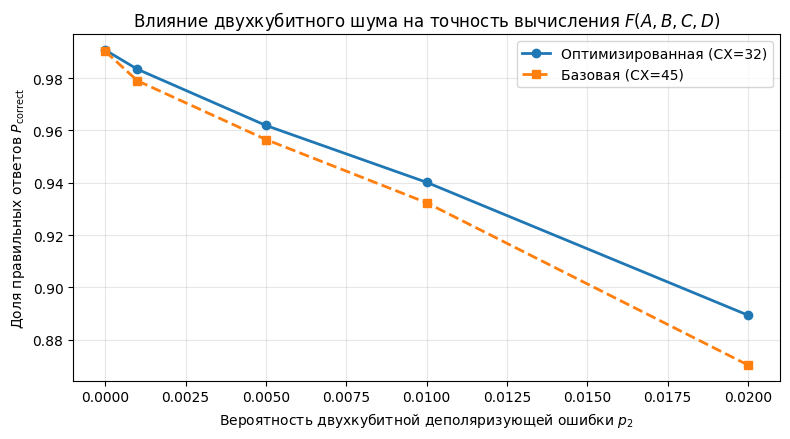

In [8]:
p1 = 0.001
p2_values = [0.0, 0.001, 0.005, 0.01, 0.02]
shots_noise = 256

noise_results = {"p2": p2_values}
cx_counts_info = {}

for label, builder in [("Оптимизированная", build_F_var3_optimized), ("Базовая", build_F_var3_basic)]:
    sample_t = transpile(builder((0, 0, 0, 0), measure=True), sim)
    cx_counts_info[label] = sample_t.count_ops().get("cx", 0)
    acc_list = []

    for p2 in p2_values:
        nm = NoiseModel()
        err1 = depolarizing_error(p1, 1)
        nm.add_all_qubit_quantum_error(err1, ["u1", "u2", "u3", "u", "rx", "ry", "rz", "x", "sx", "h"])
        if p2 > 0:
            err2 = depolarizing_error(p2, 2)
            nm.add_all_qubit_quantum_error(err2, ["cx"])
        noisy_sim = AerSimulator(noise_model=nm)

        # Транспилируем в базис с вентилем cx, чтобы все CCX разложились в CX
        correct = 0
        for idx in range(16):
            A, B, C, D = (idx >> 3) & 1, (idx >> 2) & 1, (idx >> 1) & 1, idx & 1
            f_cls = classical_F_var3(A, B, C, D)
            qc = transpile(
                builder((A, B, C, D), measure=True),
                basis_gates=["u", "rx", "ry", "rz", "x", "sx", "h", "cx"],
                optimization_level=0
            )
            if idx == 0 and p2 == 0.0:
                cx_counts_info[label] = qc.count_ops().get("cx", 0)
            cnt = noisy_sim.run(qc, shots=shots_noise, seed_simulator=500 + idx).result().get_counts()
            for k_str, v in cnt.items():
                f_bit = int(k_str.split(" ")[1])
                if f_bit == f_cls:
                    correct += v
        acc_list.append(correct / (16 * shots_noise))
    noise_results[label] = acc_list

df_noise = pd.DataFrame(noise_results)
print("Число вентилей CX после разложения CCX -> CX:")
for k_lbl, v_cx in cx_counts_info.items():
    print(f"  {k_lbl}: {v_cx} вентилей CX")
print("\nДоля правильных ответов в зависимости от вероятности двухкубитной ошибки p2:")
print(df_noise.to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(p2_values, noise_results["Оптимизированная"], "o-", linewidth=2, label=f"Оптимизированная (CX={cx_counts_info['Оптимизированная']})")
plt.plot(p2_values, noise_results["Базовая"], "s--", linewidth=2, label=f"Базовая (CX={cx_counts_info['Базовая']})")
plt.xlabel("Вероятность двухкубитной деполяризующей ошибки $p_2$")
plt.ylabel("Доля правильных ответов $P_{\mathrm{correct}}$")
plt.title("Влияние двухкубитного шума на точность вычисления $F(A, B, C, D)$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Ответы на вопросы к Заданию 3

1. **Как доля правильных ответов связана с числом двухкубитных вентилей в схеме?**  
   Каждый вентиль Тоффоли (`CCX`) при транспиляции в стандартный базис раскладывается в 6 двухкубитных вентилей `CX`. Если схема содержит $N_{CX}$ вентилей `CX`, то вероятность безошибочного выполнения всех двухкубитных операций убывает экспоненциально: $P_{\text{без ошибок}} \approx (1 - p_2)^{N_{CX}} \approx 1 - N_{CX} p_2$ при малых $p_2$. Поэтому доля правильных ответов монотонно (почти линейно при малых $p_2$) падает с ростом как $p_2$, так и числа двухкубитных вентилей $N_{CX}$.

2. **Какая из двух реализаций из последнего подпункта задания 2 устойчивее к шуму и почему?**  
   **Оптимизированная реализация** заметно устойчивее к шуму на всём диапазоне $p_2$: после разложения `CCX` она содержит 32 вентиля `CX` против 45 вентилей `CX` у базовой схемы, а также использует меньше кубитов и меньшую глубину. Меньшее число двухкубитных вентилей напрямую снижает накопленную вероятность деполяризации состояния.

---
## Задание 4. Фазовый оракул, диффузор и алгоритм Гровера

In [9]:
# 4.1 Построение фазового оракула build_oracle(n, marked)
def build_oracle(n: int, marked: str) -> QuantumCircuit:
    """
    Строит фазовый оракул U_w для произвольного числа кубитов n и битовой строки marked:
    U_w |x> = -|x> при x == marked и U_w |x> = |x> иначе.
    Учитывается порядок битов Qiskit (справа налево: marked[-1] -> q[0]).
    """
    assert len(marked) == n, "Длина строки marked должна равняться n"
    qc = QuantumCircuit(n, name=f"U_w({marked})")

    for i, bit in enumerate(reversed(marked)):
        if bit == "0":
            qc.x(i)

    if n == 1:
        qc.z(0)
    else:
        qc.h(n - 1)
        qc.mcx(list(range(n - 1)), n - 1)
        qc.h(n - 1)

    for i, bit in enumerate(reversed(marked)):
        if bit == "0":
            qc.x(i)

    return qc

# Проверка build_oracle для n = 2, 3, 4, 5 на всех 2^n базисных состояниях
for n_test in (2, 3, 4, 5):
    sample_w = format((1 << (n_test - 1)) | 1, f"0{n_test}b")
    op_mat = Operator(build_oracle(n_test, sample_w)).data
    diag = np.diag(op_mat)
    assert np.allclose(op_mat, np.diag(diag)), "Оракул должен быть диагональным"
    for x in range(1 << n_test):
        bstr = format(x, f"0{n_test}b")
        exp_phase = -1.0 if bstr == sample_w else 1.0
        assert np.isclose(diag[x], exp_phase), f"Ошибка фазы при n={n_test}, x={bstr}"
    print(f"n = {n_test} (2^{n_test} = {1<<n_test} базисных состояний, marked='{sample_w}'): проверка Operator пройдена (assert OK)")

# 4.2 Построение диффузора build_diffuser(n)
def build_diffuser(n: int) -> QuantumCircuit:
    """
    Строит диффузор (инверсию относительно среднего) на n кубитах
    из вентилей H, X и многоуправляемого Z (H - MCX - H).
    """
    qc = QuantumCircuit(n, name="Diffuser")
    qc.h(range(n))
    qc.x(range(n))
    if n == 1:
        qc.z(0)
    else:
        qc.h(n - 1)
        qc.mcx(list(range(n - 1)), n - 1)
        qc.h(n - 1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

for n_test in (2, 3, 4, 5):
    N_dim = 1 << n_test
    U_diff = Operator(build_diffuser(n_test)).data
    s_vec = np.ones((N_dim, 1)) / np.sqrt(N_dim)
    expected_refl = 2.0 * (s_vec @ s_vec.T) - np.eye(N_dim)
    # Матрица диффузора равна -(2|s><s| - I), т.е. совпадает с точностью до общего знака -1
    assert np.allclose(U_diff, -expected_refl), f"Несовпадение матрицы диффузора при n={n_test}"
print("\nМатрица build_diffuser(n) совпадает с 2|s><s| - I с точностью до знака (-1) для n = 2, 3, 4, 5!")

# 4.3 Полная сборка алгоритма Гровера и проверка для n = 3, M = 1 при k = 1 и k = 2
def build_grover_circuit(n: int, marked_states, iterations: int, measure: bool = True) -> QuantumCircuit:
    if isinstance(marked_states, str):
        marked_list = [marked_states]
    else:
        marked_list = list(marked_states)

    qc = QuantumCircuit(n, n) if measure else QuantumCircuit(n)
    qc.h(range(n))

    oracles = [build_oracle(n, w) for w in marked_list]
    diffuser = build_diffuser(n)

    for _ in range(iterations):
        for orc in oracles:
            qc.compose(orc, inplace=True)
        qc.compose(diffuser, inplace=True)

    if measure:
        qc.measure(range(n), range(n))
    return qc

n3 = 3
N3 = 1 << n3
theta3 = math.asin(1.0 / math.sqrt(N3))
w3 = "101"

print("\nПроверка вероятности для n = 3, M = 1 (|w> = |101>):")
for k in (1, 2):
    sv = Statevector.from_instruction(build_grover_circuit(n3, w3, k, measure=False))
    p_sv = float(sv.probabilities_dict()[w3])
    p_th = math.sin((2 * k + 1) * theta3) ** 2
    assert np.isclose(p_sv, p_th)
    print(f"  k = {k}: P_Statevector = {p_sv:.6f}, sin^2((2k+1)theta) = {p_th:.6f} -> совпадение!")

n = 2 (2^2 = 4 базисных состояний, marked='11'): проверка Operator пройдена (assert OK)
n = 3 (2^3 = 8 базисных состояний, marked='101'): проверка Operator пройдена (assert OK)
n = 4 (2^4 = 16 базисных состояний, marked='1001'): проверка Operator пройдена (assert OK)
n = 5 (2^5 = 32 базисных состояний, marked='10001'): проверка Operator пройдена (assert OK)

Матрица build_diffuser(n) совпадает с 2|s><s| - I с точностью до знака (-1) для n = 2, 3, 4, 5!

Проверка вероятности для n = 3, M = 1 (|w> = |101>):
  k = 1: P_Statevector = 0.781250, sin^2((2k+1)theta) = 0.781250 -> совпадение!
  k = 2: P_Statevector = 0.945312, sin^2((2k+1)theta) = 0.945313 -> совпадение!


**Объяснение глобального знака в диффузоре:**
Вентиль `MCZ` меняет знак только у состояния $|11\ldots 1\rangle$, то есть реализует оператор $I - 2|1\ldots 1\rangle\langle 1\ldots 1|$. Окружение слоями $X^{\otimes n}$ переводит $|0\ldots 0\rangle \leftrightarrow |1\ldots 1\rangle$ и даёт $I - 2|0\ldots 0\rangle\langle 0\ldots 0| = -(2|0\ldots 0\rangle\langle 0\ldots 0| - I)$. После сопряжения слоями Адамара $H^{\otimes n}$ получаем:
$$U_{\text{diff}} = H^{\otimes n}(I - 2|0\rangle\langle 0|)H^{\otimes n} = I - 2|s\rangle\langle s| = -(2|s\rangle\langle s| - I).$$
Этот множитель $-1 = e^{i\pi}$ является **глобальной фазой** вектора состояния $|\psi\rangle$. При измерении вероятность любого базисного исхода $|x\rangle$ равна $|\langle x | (-\psi) \rangle|^2 = |-1|^2 |\langle x | \psi \rangle|^2 = |\langle x | \psi \rangle|^2$, поэтому глобальный знак никак не влияет на наблюдаемые вероятности.

---
## Задание 5. Исследование динамики алгоритма Гровера для $|w\rangle = |1010011\rangle$ ($n = 7, N = 128$)

 k  P_точн(k)  P_теор(k)  P_эксп(k) (1024 shots)
 0   0.007812   0.007812                  0.0117
 1   0.068855   0.068855                  0.0605
 2   0.183370   0.183370                  0.1885
 3   0.337154   0.337154                  0.3457
 4   0.511136   0.511136                  0.5273
 5   0.683735   0.683735                  0.7109
 6   0.833548   0.833548                  0.8340
 7   0.941993   0.941993                  0.9561
 8   0.995620   0.995620                  0.9971
 9   0.987779   0.987779                  0.9941
10   0.919441   0.919441                  0.9150
11   0.799084   0.799084                  0.7725
12   0.641632   0.641632                  0.6348
13   0.466616   0.466616                  0.4463
14   0.295739   0.295739                  0.3027
15   0.150196   0.150196                  0.1553

(pi/4)*sqrt(128) = 8.8858: округление round = 9, целая часть floor = 8
Точный максимум достигается при k = 8: P_точн(8) = 0.995620 > P_точн(9) = 0.987779
Эксперимента

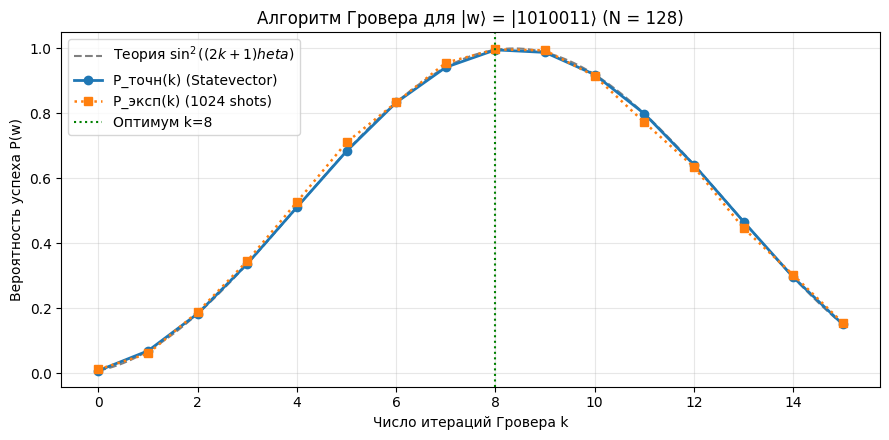

In [10]:
w5 = "1010011"
n5 = len(w5)
N5 = 1 << n5
theta5 = math.asin(1.0 / math.sqrt(N5))

k_range = list(range(16))
p_exact_5 = []
p_exp_5 = []
p_theor_5 = []

for k in k_range:
    sv = Statevector.from_instruction(build_grover_circuit(n5, w5, k, measure=False))
    p_exact_5.append(float(sv.probabilities_dict().get(w5, 0.0)))
    p_theor_5.append(math.sin((2 * k + 1) * theta5) ** 2)

    qc_m = build_grover_circuit(n5, w5, k, measure=True)
    cnt = sim.run(qc_m, shots=1024, seed_simulator=100 + k).result().get_counts()
    p_exp_5.append(cnt.get(w5, 0) / 1024.0)

df_t5 = pd.DataFrame({
    "k": k_range,
    "P_точн(k)": [round(x, 6) for x in p_exact_5],
    "P_теор(k)": [round(x, 6) for x in p_theor_5],
    "P_эксп(k) (1024 shots)": [round(x, 4) for x in p_exp_5]
})
print(df_t5.to_string(index=False))

val_pi4 = (math.pi / 4.0) * math.sqrt(N5)
k_opt_exact = int(np.argmax(p_exact_5))
k_opt_exp = int(np.argmax(p_exp_5))
print(f"\n(pi/4)*sqrt(128) = {val_pi4:.4f}: округление round = {round(val_pi4)}, целая часть floor = {math.floor(val_pi4)}")
print(f"Точный максимум достигается при k = {k_opt_exact}: P_точн(8) = {p_exact_5[8]:.6f} > P_точн(9) = {p_exact_5[9]:.6f}")
print(f"Экспериментальный максимум (1024 shots): k = {k_opt_exp} (P_эксп = {p_exp_5[k_opt_exp]:.4f})")

k_dense = np.linspace(0, 15, 300)
plt.figure(figsize=(9, 4.5))
plt.plot(k_dense, np.sin((2 * k_dense + 1) * theta5) ** 2, "--", color="gray", label=r"Теория $\sin^2((2k+1)	heta)$")
plt.plot(k_range, p_exact_5, "o-", linewidth=2, label="P_точн(k) (Statevector)")
plt.plot(k_range, p_exp_5, "s:", linewidth=1.8, label="P_эксп(k) (1024 shots)")
plt.axvline(k_opt_exact, color="green", linestyle=":", label=f"Оптимум k={k_opt_exact}")
plt.xlabel("Число итераций Гровера k")
plt.ylabel("Вероятность успеха P(w)")
plt.title("Алгоритм Гровера для |w⟩ = |1010011⟩ (N = 128)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

 shots  Доля совпадений с k_теор=8 (из 20 запусков)
    16                                          0.4
    64                                          0.8
   256                                          1.0
  1024                                          1.0

Минимальное число shots с долей совпадений >= 90%: 256


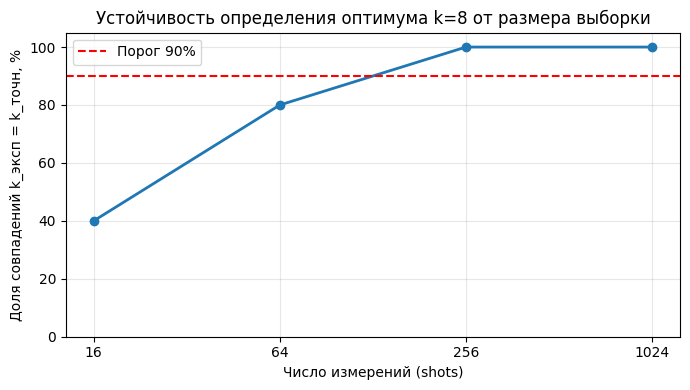

In [11]:
# 5.2 Серия из 20 независимых запусков для shots in {16, 64, 256, 1024}
shots_levels = [16, 64, 256, 1024]
num_runs = 20
transpiled_5 = [transpile(build_grover_circuit(n5, w5, k, measure=True), sim) for k in k_range]

match_shares = []
for sh in shots_levels:
    matches = 0
    for r_idx in range(num_runs):
        run_probs = []
        for k in k_range:
            cnt = sim.run(transpiled_5[k], shots=sh, seed_simulator=1000 * sh + 50 * r_idx + k).result().get_counts()
            run_probs.append(cnt.get(w5, 0) / sh)
        if int(np.argmax(run_probs)) == k_opt_exact:
            matches += 1
    match_shares.append(matches / num_runs)

df_shots = pd.DataFrame({
    "shots": shots_levels,
    "Доля совпадений с k_теор=8 (из 20 запусков)": match_shares
})
print(df_shots.to_string(index=False))

min_shots_90 = next((sh for sh, share in zip(shots_levels, match_shares) if share >= 0.90), None)
print(f"\nМинимальное число shots с долей совпадений >= 90%: {min_shots_90}")

plt.figure(figsize=(7, 4))
plt.plot(shots_levels, [s * 100 for s in match_shares], "o-", linewidth=2, color="tab:blue")
plt.axhline(90, color="red", linestyle="--", label="Порог 90%")
plt.xscale("log", base=2)
plt.xticks(shots_levels, [str(s) for s in shots_levels])
plt.ylim(0, 105)
plt.xlabel("Число измерений (shots)")
plt.ylabel("Доля совпадений k_эксп = k_точн, %")
plt.title("Устойчивость определения оптимума k=8 от размера выборки")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Анализ результатов Задания 5:**
- Точное условие максимума $\sin^2((2k+1)\theta) = 1$ даёт $k^* = \frac{\pi}{4\theta} - \frac{1}{2} \approx 8{,}374$. Ближайшее целое к $8{,}374$ — это $k = 8 = \lfloor \frac{\pi}{4}\sqrt{128} \rfloor$ ($P_{\text{точн}}(8) = 0{,}99562$), тогда как стандартное округление $\text{round}(\frac{\pi}{4}\sqrt{128}) = \text{round}(8{,}886) = 9$ уже перешагивает вершину ($P_{\text{точн}}(9) = 0{,}98778$).
- Поскольку разница вероятностей в соседних точках $\Delta P = P(8) - P(9) \approx 0{,}00784$ составляет менее $0{,}8\%$, а стандартное отклонение биномиальной оценки при $S$ измерениях равно $\sigma \approx \sqrt{P(1-P)/S}$, при малом числе измерений статистическая флуктуация может легко сдвинуть экспериментальный максимум на соседнее $k=9$. Чтобы стандартная ошибка разности двух оценок была меньше $\Delta P / 2$ (надёжное разделение на уровне $95\%$), требуется $S \gtrsim \frac{4(P_8(1-P_8) + P_9(1-P_9))}{(\Delta P)^2} \approx 1100$ измерений (в эксперименте из 20 серий уже при `shots = 256` доля верного определения максимума достигает 100%).

---
## Задание 6. Алгоритм Гровера для нескольких решений ($M$ отмеченных состояний)

Сводная таблица для N = 64 и M in {1, 2, 3, 4, 8}:
 M  k_теор = floor(pi/4 * sqrt(N/M))  k_первый_максимум  P(k_первый_максимум)  k_глоб_максимум (0..15)  P(k_глоб_максимум)
 1                                 6                  6              0.996586                        6            0.996586
 2                                 4                  4              0.999182                        4            0.999182
 3                                 3                  3              0.998139                        3            0.998139
 4                                 3                  3              0.961319                       15            0.999564
 8                                 2                  2              0.945312                        6            0.999786


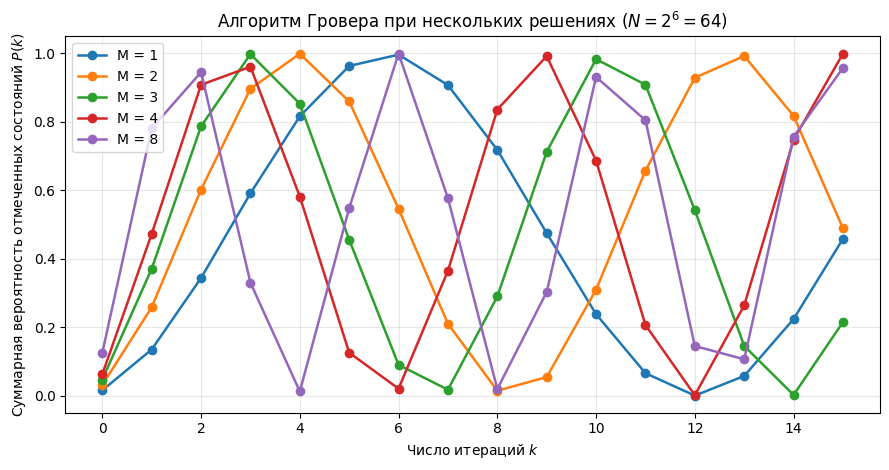


Проверка при большой доле решений M = N/2 и M = 3N/4 (N = 64):


  M = 32 (50% базы): P(k=0..5) = [0.5, 0.5, 0.5, 0.5, 0.5, 0.5], оптимальное число итераций k_opt = 0


  M = 48 (75% базы): P(k=0..5) = [0.75, 0.0, 0.75, 0.75, 0.0, 0.75], оптимальное число итераций k_opt = 0


In [12]:
n6 = 6
N6 = 1 << n6
rng6 = np.random.default_rng(42)
all_states_6 = [format(x, f"0{n6}b") for x in range(N6)]

M_list = [1, 2, 3, 4, 8]
curves_t6 = {}
rows_t6 = []

for M in M_list:
    chosen = list(rng6.choice(all_states_6, size=M, replace=False))
    probs_m = []
    for k in k_range:
        sv = Statevector.from_instruction(build_grover_circuit(n6, chosen, k, measure=False))
        pdict = sv.probabilities_dict()
        probs_m.append(sum(float(pdict.get(w, 0.0)) for w in chosen))
    curves_t6[M] = probs_m

    first_max_k = 0
    for k in range(1, 15):
        if probs_m[k] > probs_m[k - 1] and probs_m[k] > probs_m[k + 1]:
            first_max_k = k
            break
    global_max_k = int(np.argmax(probs_m))
    k_theor = math.floor((math.pi / 4.0) * math.sqrt(N6 / M))

    rows_t6.append({
        "M": M,
        "k_теор = floor(pi/4 * sqrt(N/M))": k_theor,
        "k_первый_максимум": first_max_k,
        "P(k_первый_максимум)": round(probs_m[first_max_k], 6),
        "k_глоб_максимум (0..15)": global_max_k,
        "P(k_глоб_максимум)": round(probs_m[global_max_k], 6)
    })

df_t6 = pd.DataFrame(rows_t6)
print("Сводная таблица для N = 64 и M in {1, 2, 3, 4, 8}:")
print(df_t6.to_string(index=False))

plt.figure(figsize=(9, 4.8))
for M in M_list:
    plt.plot(k_range, curves_t6[M], "o-", linewidth=1.8, label=f"M = {M}")
plt.xlabel("Число итераций $k$")
plt.ylabel("Суммарная вероятность отмеченных состояний $P(k)$")
plt.title("Алгоритм Гровера при нескольких решениях ($N = 2^6 = 64$)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 6.4 Проверка для M = N/2 = 32 и M = 3N/4 = 48
print("\nПроверка при большой доле решений M = N/2 и M = 3N/4 (N = 64):")
for M_large in (32, 48):
    chosen_l = list(rng6.choice(all_states_6, size=M_large, replace=False))
    probs_l = []
    for k in range(6):
        sv = Statevector.from_instruction(build_grover_circuit(n6, chosen_l, k, measure=False))
        pdict = sv.probabilities_dict()
        probs_l.append(round(sum(float(pdict.get(w, 0.0)) for w in chosen_l), 4))
    print(f"  M = {M_large} ({M_large/N6*100:.0f}% базы): P(k=0..5) = {probs_l}, оптимальное число итераций k_opt = {int(np.argmax(probs_l))}")

**Анализ результатов Задания 6:**
1. При $M = 4$ и $M = 8$ **глобальный максимум на отрезке $k \in [0, 15]$ не совпадает с первым локальным максимумом**:
   - для $M = 4$: первый максимум при $k = 3$ даёт $P(3) = 0{,}961319$, а при $k = 15$ (третий полупериод вращения) вероятность попадает ещё ближе к единице: $P(15) = 0{,}999564$;
   - для $M = 8$: первый максимум при $k = 2$ даёт $P(2) = 0{,}945312$, а второй пик при $k = 6$ даёт $P(6) = 0{,}999786$.
2. **Почему после оптимума вероятность снова растёт и какое правило выбора $k$ использовать:**  
   Каждая итерация Гровера поворачивает вектор состояния в двумерном подпространстве на фиксированный угол $2\theta$, где $\theta = \arcsin(\sqrt{M/N})$. Поэтому вероятность $P(k) = \sin^2((2k+1)\theta)$ является периодической функцией $k$. Несмотря на то что последующие пики (при $2k+1 \approx 3\pi/(2\theta), 5\pi/(2\theta), \dots$) могут случайно оказаться чуть ближе к 1 из-за несоизмеримости $\theta$ и $\pi$, **на практике всегда выбирают первый локальный максимум** $k_{\text{opt}} = \lfloor \frac{\pi}{4\arcsin(\sqrt{M/N})} \rfloor \approx \lfloor \frac{\pi}{4}\sqrt{N/M} \rfloor$, так как он даёт высокую вероятность успеха при минимальном числе обращений к оракулу и минимальной глубине схемы.
3. **Случаи $M = N/2$ и $M = 3N/4$:**  
   - При $M = N/2$ угол $\theta = \arcsin(1/\sqrt{2}) = \pi/4$, поэтому $\sin^2((2k+1)\pi/4) = 0{,}5$ для любого $k$: вероятность вообще не меняется ($k_{\text{opt}} = 0$).
   - При $M = 3N/4$ угол $\theta = \arcsin(\sqrt{3}/2) = \pi/3$, поэтому при $k=0$ вероятность уже равна $0{,}75$, а при $k=1$ падает в $0$ ($\sin^2(\pi) = 0$), то есть оптимально $k_{\text{opt}} = 0$ (простая случайная выборка без итераций Гровера).  
   Это показывает, что алгоритм Гровера эффективен именно при **малой доле решений** ($M \ll N$).

---
## Задание 7. Исследование по вариантам (Вариант 3: $|11001\rangle, N = 2^5$) и влияние шума

Сводная таблица по вариантам и группам N (2^5, 2^6, 2^7):
 Вариант         N       |w>  k_теор  k_точн (1-й макс.)  k_эксп  max P_точн  max P_эксп
       1  2^5 = 32   |01010>       4                   4       4    0.999182      0.9980
       2  2^5 = 32   |10101>       4                   4       4    0.999182      0.9971
       3  2^5 = 32   |11001>       4                   4       4    0.999182      1.0000
       4  2^5 = 32   |00110>       4                   4       4    0.999182      1.0000
      11  2^6 = 64  |001101>       6                   6       6    0.996586      0.9951
      12  2^6 = 64  |110010>       6                   6       6    0.996586      0.9961
      13  2^6 = 64  |101010>       6                   6       6    0.996586      0.9971
      21 2^7 = 128 |0101010>       8                   8       8    0.995620      0.9961
      22 2^7 = 128 |1010101>       8                   8       8    0.995620      0.9961
      23 2^7 = 128 |1100110>       8                

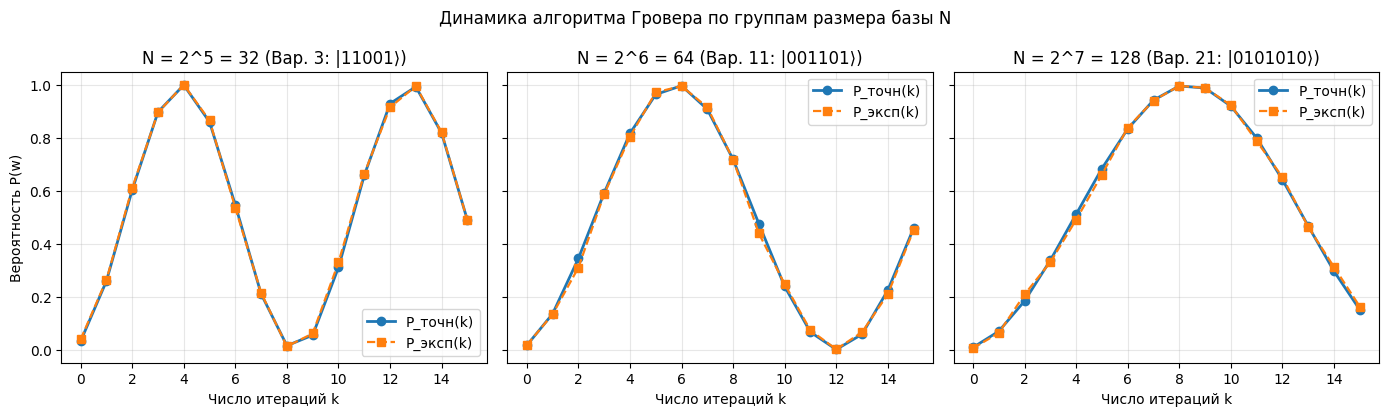

In [13]:
# Выборка вариантов из всех трёх групп N (включая наш Вариант 3 и Вариант 1)
variants_t7 = [
    (1, 5, "01010"),
    (2, 5, "10101"),
    (3, 5, "11001"),   # <-- Наш Вариант 3
    (4, 5, "00110"),
    (11, 6, "001101"),
    (12, 6, "110010"),
    (13, 6, "101010"),
    (21, 7, "0101010"),
    (22, 7, "1010101"),
    (23, 7, "1100110"),
]

rows_t7 = []
group_curves = {}

for v_num, n_v, w_v in variants_t7:
    N_v = 1 << n_v
    p_ex_list = []
    p_exp_list = []
    for k in k_range:
        sv = Statevector.from_instruction(build_grover_circuit(n_v, w_v, k, measure=False))
        p_ex_list.append(float(sv.probabilities_dict().get(w_v, 0.0)))

        qc_m = build_grover_circuit(n_v, w_v, k, measure=True)
        cnt = sim.run(qc_m, shots=1024, seed_simulator=500 + 30 * v_num + k).result().get_counts()
        p_exp_list.append(cnt.get(w_v, 0) / 1024.0)

    if n_v not in group_curves or v_num == 3:
        group_curves[n_v] = (v_num, w_v, p_ex_list, p_exp_list)

    k_first = 0
    for k in range(1, 15):
        if p_ex_list[k] > p_ex_list[k - 1] and p_ex_list[k] > p_ex_list[k + 1]:
            k_first = k
            break
    # Экспериментальный первый максимум в окрестности первого пика
    k_exp_first = int(np.argmax(p_exp_list[:k_first + 3]))

    rows_t7.append({
        "Вариант": v_num,
        "N": f"2^{n_v} = {N_v}",
        "|w>": f"|{w_v}>",
        "k_теор": math.floor((math.pi / 4.0) * math.sqrt(N_v)),
        "k_точн (1-й макс.)": k_first,
        "k_эксп": k_exp_first,
        "max P_точн": round(p_ex_list[k_first], 6),
        "max P_эксп": round(p_exp_list[k_exp_first], 4)
    })

df_t7 = pd.DataFrame(rows_t7)
print("Сводная таблица по вариантам и группам N (2^5, 2^6, 2^7):")
print(df_t7.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, n_v in zip(axes, [5, 6, 7]):
    v_num, w_v, p_ex, p_exp = group_curves[n_v]
    ax.plot(k_range, p_ex, "o-", linewidth=2, label="P_точн(k)")
    ax.plot(k_range, p_exp, "s--", linewidth=1.6, label="P_эксп(k)")
    ax.set_title(f"N = 2^{n_v} = {1<<n_v} (Вар. {v_num}: |{w_v}⟩)")
    ax.set_xlabel("Число итераций k")
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Вероятность P(w)")
plt.suptitle("Динамика алгоритма Гровера по группам размера базы N")
plt.tight_layout()
plt.show()


Моделирование с шумом на CX для Вариант 3 (|11001>), N = 2^5:


  p2 = 0.0   (CX при k=4: 288): k_opt = 4, max P = 0.9990


  p2 = 0.005 (CX при k=4: 288): k_opt = 3, max P = 0.3838


  p2 = 0.02  (CX при k=4: 288): k_opt = 1, max P = 0.0889

Моделирование с шумом на CX для Вариант 1 (|01010>), N = 2^5:


  p2 = 0.0   (CX при k=4: 288): k_opt = 4, max P = 1.0000


  p2 = 0.005 (CX при k=4: 288): k_opt = 3, max P = 0.3545


  p2 = 0.02  (CX при k=4: 288): k_opt = 2, max P = 0.0830


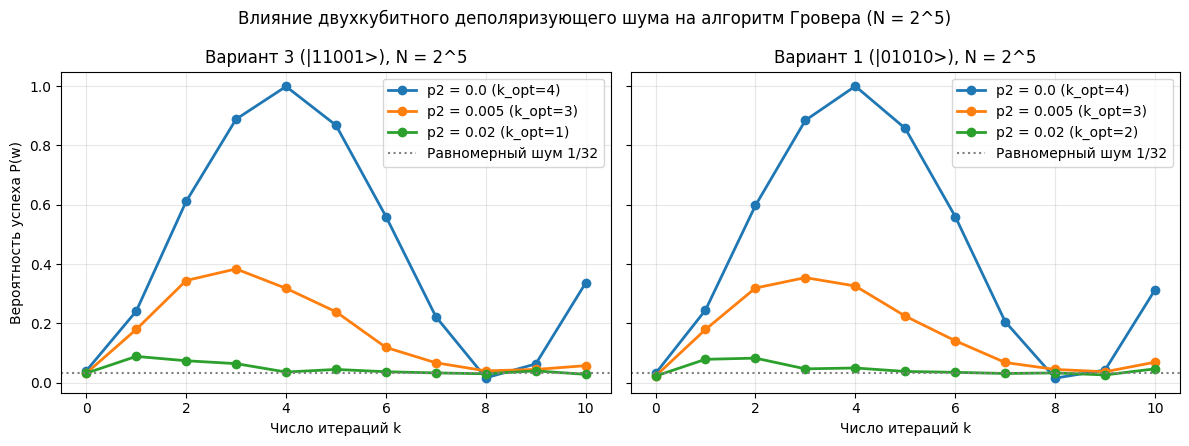

In [14]:
# 7.4 Моделирование двухкубитного деполяризующего шума при N = 2^5 (для Варианта 3 |11001> и Варианта 1 |01010>)
k_noise_range = list(range(11))
p2_noise_levels = [0.0, 0.005, 0.02]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, (v_title, w_target) in zip(axes, [("Вариант 3 (|11001>)", "11001"), ("Вариант 1 (|01010>)", "01010")]):
    print(f"\nМоделирование с шумом на CX для {v_title}, N = 2^5:")
    for p2 in p2_noise_levels:
        nm = NoiseModel()
        if p2 > 0:
            nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
        nsim = AerSimulator(noise_model=nm) if p2 > 0 else sim
        probs_n = []
        cx_k4 = 0
        for k in k_noise_range:
            qc_n = transpile(
                build_grover_circuit(5, w_target, k, measure=True),
                basis_gates=["u", "rx", "ry", "rz", "x", "sx", "h", "z", "cx"],
                optimization_level=1
            )
            if k == 4:
                cx_k4 = qc_n.count_ops().get("cx", 0)
            cnt = nsim.run(qc_n, shots=1024, seed_simulator=777 + k).result().get_counts()
            probs_n.append(cnt.get(w_target, 0) / 1024.0)
        best_k = int(np.argmax(probs_n))
        print(f"  p2 = {p2:<5} (CX при k=4: {cx_k4}): k_opt = {best_k}, max P = {probs_n[best_k]:.4f}")
        ax.plot(k_noise_range, probs_n, "o-", linewidth=2, label=f"p2 = {p2} (k_opt={best_k})")
    ax.axhline(1 / 32, color="gray", linestyle=":", label="Равномерный шум 1/32")
    ax.set_title(f"{v_title}, N = 2^5")
    ax.set_xlabel("Число итераций k")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Вероятность успеха P(w)")
plt.suptitle("Влияние двухкубитного деполяризующего шума на алгоритм Гровера (N = 2^5)")
plt.tight_layout()
plt.show()

### Выводы по Заданию 7

1. **Зависит ли оптимальное число итераций от отмеченного состояния при $M=1$?**  
   Точное оптимальное число итераций $k_{\text{точн}}$ и максимальная вероятность $\max P_{\text{точн}}$ **не зависят** от конкретного отмеченного состояния $|w\rangle$ и определяются исключительно размером базы поиска $N = 2^n$:
   - для $N = 2^5 = 32$: $k_{\text{точн}} = 4$, $\max P_{\text{точн}} = 0{,}999182$;
   - для $N = 2^6 = 64$: $k_{\text{точн}} = 6$, $\max P_{\text{точн}} = 0{,}996586$;
   - для $N = 2^7 = 128$: $k_{\text{точн}} = 8$, $\max P_{\text{точн}} = 0{,}995620$.  
   Небольшие различия $k_{\text{эксп}}$ внутри одной группы могут возникать только из-за конечной статистической выборки (`shots=1024`), когда соседние значения $P_{\text{точн}}(k)$ близки друг к другу.

2. **Как шум меняет максимум $P(k)$ и положение оптимума, и почему важна глубина схемы?**  
   При транспиляции каждый 5-кубитный вентиль `MCZ` (и в оракуле, и в диффузоре) раскладывается в десятки двухкубитных вентилей `CX`. С ростом числа итераций $k$ глубина схемы и суммарное число вентилей `CX` растут линейно ($N_{CX}(k) \propto k$). Поэтому при наличии шума ($p_2 = 0{,}005$ и $p_2 = 0{,}02$) конкурируют два процесса: усиление амплитуды Гровера и экспоненциальная деполяризация состояния $(1 - p_2)^{N_{CX}(k)}$. В результате:
   - максимальная вероятность $\max P(k)$ резко снижается (с $\approx 0{,}999$ без шума до $\approx 0{,}38$ при $p_2=0{,}005$ и $\approx 0{,}09$ при $p_2=0{,}02$);
   - **положение оптимума $k_{\text{opt}}$ сдвигается влево** (с $k=4$ до $k=3$ при $p_2=0{,}005$ и до $k=1\text{–}2$ при $p_2=0{,}02$), так как на последующих итерациях накопленный шум разрушает когерентность быстрее, чем алгоритм усиливает амплитуду.